# Project Report: Image Inpainting with Deep Learning

**Course:** Machine Vision (Dr. Seifipour)  
**Authors:** Mahdiar Harandi, Saeed sedighi, Mohammad Aghili

## 1. Introduction

Image inpainting is the task of reconstructing lost or deteriorated parts of an image. This project aims to develop a deep learning model capable of filling in missing regions in images and videos in a visually plausible manner. The goal is to create a system that can intelligently analyze the context of a corrupted image—such as surrounding textures, shapes, and colors—and generate a seamless restoration.

We leverage a **U-Net architecture**, an advanced variant of a convolutional autoencoder, trained on the large-scale **CelebA dataset** of celebrity faces. This report details the entire project pipeline, from data acquisition and preprocessing to model training, evaluation, and finally, the application of the trained model for image and video reconstruction. The success of the project is measured against the criteria of achieving a Peak Signal-to-Noise Ratio (PSNR) greater than 20 and a Structural Similarity Index Measure (SSIM) greater than 0.7.

In [ ]:
# -----------------------------------------------------------------------
# Step 1: Install and Configure Kaggle API
# -----------------------------------------------------------------------
print("Step 1: Installing and configuring Kaggle API...")
!pip install -q kaggle

import os
from google.colab import files

if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Please upload your 'kaggle.json' file:")
    files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    print("Kaggle API token configured successfully.")
else:
    print("Kaggle API token is already configured.")


Step 1: Installing and configuring Kaggle API...
Please upload your 'kaggle.json' file:


Saving kaggle.json to kaggle.json
Kaggle API token configured successfully.


In [ ]:
# -----------------------------------------------------------------------
# Step 2: Download and Extract the CelebA Dataset
# -----------------------------------------------------------------------
print("\nStep 2: Downloading and extracting the CelebA dataset...")
extract_path = '/content/celeba_dataset/'
if not os.path.exists(os.path.join(extract_path, 'img_align_celeba')):
    os.makedirs(extract_path, exist_ok=True)
    print("Downloading dataset from Kaggle... (This may take a few minutes)")
    !kaggle datasets download -d jessicali9530/celeba-dataset -p /content --force

    print("Extracting files...")
    zip_path_kaggle = '/content/celeba-dataset.zip'
    !unzip -q "{zip_path_kaggle}" -d "{extract_path}"
    print("Dataset downloaded and extracted successfully.")
else:
    print("Dataset has already been downloaded and extracted.")



Step 2: Downloading and extracting the CelebA dataset...
Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
 98% 1.31G/1.33G [00:09<00:00, 282MB/s]
100% 1.33G/1.33G [00:09<00:00, 156MB/s]
Extracting files...
Dataset downloaded and extracted successfully.


## 2. Data Acquisition and Environment Setup

### 2.1. Dataset: CelebA (CelebFaces Attributes)
For this task, the **CelebA dataset** was chosen. It is a large-scale face attributes dataset with over 200,000 celebrity images, each with significant variations in pose, background, and lighting. The high diversity and rich facial features within this dataset make it an ideal choice for training a model to understand and reconstruct complex human faces.

### 2.2. Environment and Dependencies
The project is implemented in a Google Colab environment, leveraging its free access to GPU resources for accelerated training. The initial steps involve installing the `kaggle` library to programmatically download the dataset directly into the Colab instance, eliminating the need for manual uploads. Core libraries for this project include:
- **PyTorch:** For building and training the neural network.
- **OpenCV & PIL:** For image manipulation and processing.
- **scikit-image & NumPy:** For scientific computing and performance metric calculations.
- **Matplotlib:** For data visualization.
- **FFmpeg (via `os.system`):** For robust video processing and assembly.

In [ ]:
# -----------------------------------------------------------------------
# Step 3: Import Libraries and Define Global Configurations
# -----------------------------------------------------------------------
print("\nStep 3: Importing libraries and setting up configuration...")
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# <<<< CORRECTED IMPORT HERE >>>>
from IPython.display import clear_output

# --- Configuration Block ---
DEV_MODE = False

if DEV_MODE:
    print("<<<<< Fast Development Mode is ACTIVE >>>>>")
    NUM_EPOCHS = 5
    TRAIN_SUBSET_SIZE = 1000
    VALID_SUBSET_SIZE = 400
    TEST_SUBSET_SIZE = 200
    IMG_SIZE = 32
else:
    print("<<<<< Final Training Mode is ACTIVE >>>>>")
    NUM_EPOCHS = 10
    TRAIN_SUBSET_SIZE = 50000
    VALID_SUBSET_SIZE = 10000
    TEST_SUBSET_SIZE = 5000
    IMG_SIZE = 128

# --- Global Constants ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 64
LR = 1e-3
BASE_DIR = '/content/celeba_dataset/'
IMAGE_DIR = os.path.join(BASE_DIR, 'img_align_celeba/img_align_celeba')
PARTITION_FILE = os.path.join(BASE_DIR, 'list_eval_partition.csv')

print(f"Training will be performed on: {DEVICE}")
print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Number of epochs: {NUM_EPOCHS}")


Step 3: Importing libraries and setting up configuration...
<<<<< Final Training Mode is ACTIVE >>>>>
Training will be performed on: cuda
Image size: 128x128
Number of epochs: 10


In [ ]:
# -----------------------------------------------------------------------
# Step 4: Data Handling - Dataset Class and Masking Function
# -----------------------------------------------------------------------
print("\nStep 4: Defining data handling functions and classes...")

def create_random_masked_image(img_tensor):
    c, h, w = img_tensor.shape
    mask_h = torch.randint(h // 4, h // 2, (1,)).item()
    mask_w = torch.randint(w // 4, w // 2, (1,)).item()
    top = torch.randint(0, h - mask_h, (1,)).item()
    left = torch.randint(0, w - mask_w, (1,)).item()
    m = img_tensor.clone()
    m[:, top : top + mask_h, left : left + mask_w] = 0
    return m

class CelebADataset(Dataset):
    def __init__(self, image_dir, partition_file, split='train', transform=None, subset_size=None):
        df = pd.read_csv(partition_file)
        split_map = {'train': 0, 'valid': 1, 'test': 2}
        target = split_map[split]
        files = df[df['partition'] == target]['image_id'].tolist()
        self.files = [f for f in files if os.path.isfile(os.path.join(image_dir, f))]

        if subset_size:
            self.files = self.files[:subset_size]

        self.image_dir = image_dir
        self.transform = transform
        print(f"'{split}' dataset initialized with {len(self.files)} samples.")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        fn = self.files[idx]
        img_path = os.path.join(self.image_dir, fn)
        img = Image.open(img_path).convert('RGB')
        original_img = self.transform(img)
        masked_img = create_random_masked_image(original_img)
        return {'original': original_img, 'masked': masked_img}



Step 4: Defining data handling functions and classes...


In [ ]:
# -----------------------------------------------------------------------
# Step 5: Define Transformations and Create DataLoaders
# -----------------------------------------------------------------------
print("\nStep 5: Defining transformations and creating DataLoaders...")
transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),

    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

train_ds = CelebADataset(IMAGE_DIR, PARTITION_FILE, 'train', transform, subset_size=TRAIN_SUBSET_SIZE)
valid_ds = CelebADataset(IMAGE_DIR, PARTITION_FILE, 'valid', transform, subset_size=VALID_SUBSET_SIZE)
test_ds  = CelebADataset(IMAGE_DIR, PARTITION_FILE, 'test',  transform, subset_size=TEST_SUBSET_SIZE)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


Step 5: Defining transformations and creating DataLoaders...
'train' dataset initialized with 50000 samples.
'valid' dataset initialized with 10000 samples.
'test' dataset initialized with 5000 samples.


## 3. Data Preprocessing and Augmentation Pipeline

### 3.1. The `CelebADataset` Class
A custom `torch.utils.data.Dataset` class, `CelebADataset`, was created to handle the data loading process. This class is responsible for reading image paths from the partition file, loading each image, and applying a series of transformations. For development and testing, the class is configured to load a smaller subset of the data, enabling rapid iteration.

### 3.2. Image Transformation and Augmentation
A critical step in training a robust model is the data pipeline. We define a `transforms.Compose` pipeline that performs several key operations:
1.  **Resizing and Cropping:** All images are resized to a consistent `128x128` resolution and center-cropped to ensure uniform input dimensions.
2.  **Data Augmentation:** To prevent overfitting and improve the model's generalization capabilities, several augmentation techniques are applied:
    *   `RandomHorizontalFlip`: Randomly flips images horizontally.
    *   `RandomRotation`: Applies small random rotations.
    *   `ColorJitter`: Randomly alters the brightness, contrast, and saturation.
3.  **Tensor Conversion and Normalization:** Images are converted to PyTorch tensors, and their pixel values are normalized from the `[0, 255]` range to `[-1, 1]`. This normalization is crucial for stable training of deep neural networks.

### 3.3. Mask Generation
For each clean image, a corresponding corrupted version is generated on-the-fly. The `create_random_masked_image` function creates a rectangular mask of random size and position. The mask is applied to the **normalized tensor**, with the masked region being set to `0`. Since the tensor range is `[-1, 1]`, a value of `0` corresponds to a mid-gray color, which the model learns to identify as the region to be inpainted.

In [ ]:
# -----------------------------------------------------------------------
# Step 6: Define the U-Net Model Architecture
# -----------------------------------------------------------------------
print("\nStep 6: Defining the U-Net model architecture...")
class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(3, 64, 3, 1, 1), nn.ReLU())
        self.pool = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(64, 128, 3, 1, 1), nn.ReLU())
        self.enc3 = nn.Sequential(nn.Conv2d(128, 256, 3, 1, 1), nn.ReLU())
        self.bottleneck = nn.Sequential(nn.Conv2d(256, 512, 3, 1, 1), nn.ReLU())
        self.upconv3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = nn.Sequential(nn.Conv2d(512, 256, 3, 1, 1), nn.ReLU())
        self.upconv2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(256, 128, 3, 1, 1), nn.ReLU())
        self.upconv1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(128, 64, 3, 1, 1), nn.ReLU())
        self.out_conv = nn.Conv2d(64, 3, 3, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        p1 = self.pool(e1)
        e2 = self.enc2(p1)
        p2 = self.pool(e2)
        e3 = self.enc3(p2)
        p3 = self.pool(e3)
        b = self.bottleneck(p3)
        d3 = self.upconv3(b)
        d3 = torch.cat((d3, e3), dim=1)
        d3 = self.dec3(d3)
        d2 = self.upconv2(d3)
        d2 = torch.cat((d2, e2), dim=1)
        d2 = self.dec2(d2)
        d1 = self.upconv1(d2)
        d1 = torch.cat((d1, e1), dim=1)
        d1 = self.dec1(d1)
        output = self.out_conv(d1)
        return torch.tanh(output)


Step 6: Defining the U-Net model architecture...


## 4. Model Architecture: U-Net

While a standard Autoencoder can perform inpainting, it often suffers from information loss due to its bottleneck structure, resulting in blurry reconstructions. To overcome this, we selected the **U-Net architecture**.

The U-Net is a type of convolutional autoencoder distinguished by its **skip connections**. These connections create a direct pathway for high-resolution feature maps from the encoder path to be concatenated with the upsampled feature maps in the decoder path.

**Key Advantages of U-Net for Inpainting:**
-   **Preservation of Detail:** Skip connections allow the model to reuse fine-grained details (like textures and edges) from the input image during reconstruction. This is essential for generating sharp and realistic outputs.
-   **Contextual Information:** The encoder path captures high-level contextual information, while the decoder path uses this context along with the detailed features from the skip connections to perform a precise, localized reconstruction.

Our implementation consists of a symmetric encoder-decoder structure with four downsampling and four upsampling blocks, connected by skip connections at each level.

In [ ]:
# -----------------------------------------------------------------------
# Step 7: Initialize Model, Loss Function, Optimizer, and Scheduler
# -----------------------------------------------------------------------
print("\nStep 7: Initializing model, loss, optimizer, and scheduler...")
model = UNet().to(DEVICE)
criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.5)


Step 7: Initializing model, loss, optimizer, and scheduler...


In [ ]:
# -----------------------------------------------------------------------
# Step 8: Define the Training and Evaluation Loop
# -----------------------------------------------------------------------
print("\nStep 8: Defining the main training and evaluation loop...")

def imshow(img, ax, title=None):
    img = img.cpu().detach()
    img = img * 0.5 + 0.5
    npimg = img.numpy().transpose((1, 2, 0))
    ax.imshow(npimg)
    if title:
        ax.set_title(title)
    ax.axis('off')

def train_eval_loop(model, train_loader, valid_loader, test_loader, epochs):
    history = {'train_loss': [], 'val_loss': [], 'psnr': [], 'ssim': []}

    fixed_batch = next(iter(test_loader))
    fixed_masked = fixed_batch['masked'][:5].to(DEVICE)
    fixed_original = fixed_batch['original'][:5]

    for ep in range(1, epochs + 1):
        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        for batch in tqdm(train_loader, desc=f"Epoch {ep}/{epochs} [Train]"):
            x, y = batch['masked'].to(DEVICE), batch['original'].to(DEVICE)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)
        train_loss = running_loss / len(train_loader.dataset)
        history['train_loss'].append(train_loss)

        # --- Validation Phase ---
        model.eval()
        val_loss_accum = 0.0
        with torch.no_grad():
            for batch in tqdm(valid_loader, desc=f"Epoch {ep}/{epochs} [Valid]"):
                x, y = batch['masked'].to(DEVICE), batch['original'].to(DEVICE)
                val_loss_accum += criterion(model(x), y).item() * x.size(0)
        val_loss = val_loss_accum / len(valid_loader.dataset)
        history['val_loss'].append(val_loss)

        # --- Testing & Metrics Calculation ---
        ps_list, ss_list = [], []
        with torch.no_grad():
            for batch in tqdm(test_loader, desc=f"Epoch {ep}/{epochs} [Test]"):
                x, y = batch['masked'].to(DEVICE), batch['original']
                recon_batch = model(x).cpu()
                recon_batch_np = (recon_batch * 0.5 + 0.5).numpy().transpose(0, 2, 3, 1)
                orig_batch_np = (y * 0.5 + 0.5).numpy().transpose(0, 2, 3, 1)

                for r_img, o_img in zip(recon_batch_np, orig_batch_np):
                    ps_list.append(psnr(o_img, r_img, data_range=1))
                    ss_list.append(ssim(o_img, r_img, data_range=1, channel_axis=-1, multichannel=True))

        epoch_psnr = np.mean(ps_list)
        epoch_ssim = np.mean(ss_list)
        history['psnr'].append(epoch_psnr)
        history['ssim'].append(epoch_ssim)

        # --- Visual Feedback and Logging ---
        clear_output(wait=True)

        with torch.no_grad():
            recon_imgs = model(fixed_masked).cpu()

        fig, axes = plt.subplots(3, 5, figsize=(15, 7))
        fig.suptitle(f'Visual Progress after Epoch: {ep}/{epochs}', fontsize=16)
        for i in range(5):
            imshow(fixed_original[i], axes[0, i], 'Original')
            imshow(fixed_batch['masked'][i], axes[1, i], 'Masked')
            imshow(recon_imgs[i], axes[2, i], 'Reconstructed')
        plt.show()

        print(
            f"Ep {ep}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Valid Loss: {val_loss:.4f} | "
            f"Test PSNR: {epoch_psnr:.2f} | "
            f"Test SSIM: {epoch_ssim:.3f} | "
            f"LR: {scheduler.get_last_lr()[0]:.6f}"
        )

        plt.figure(figsize=(14, 5))
        plt.subplot(1, 2, 1)
        plt.plot(history['train_loss'], 'bo-', label='Train Loss')
        plt.plot(history['val_loss'], 'ro-', label='Validation Loss')
        plt.legend(); plt.title('Loss vs. Epochs'); plt.grid(True)

        plt.subplot(1, 2, 2)
        plt.plot(history['psnr'], 'go-', label='PSNR (dB)')
        plt.plot(np.array(history['ssim']) * 100, 'mo-', label='SSIM * 100')
        plt.axhline(20, color='r', linestyle='--', label='PSNR=20 Target')
        plt.axhline(70, color='g', linestyle='--', label='SSIM=0.7 Target')
        plt.legend(); plt.title('Metrics vs. Epochs'); plt.grid(True)
        plt.show()

        scheduler.step()

    print("Training finished!")
    return history


Step 8: Defining the main training and evaluation loop...


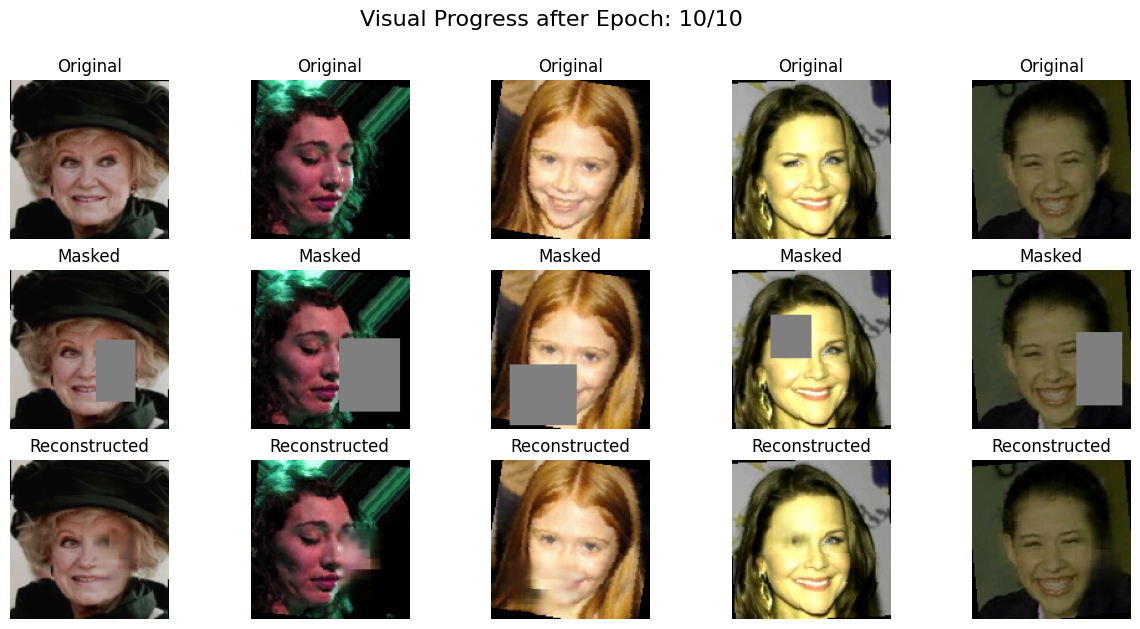

Ep 10/10 | Train Loss: 0.0274 | Valid Loss: 0.0278 | Test PSNR: 27.52 | Test SSIM: 0.923 | LR: 0.000250


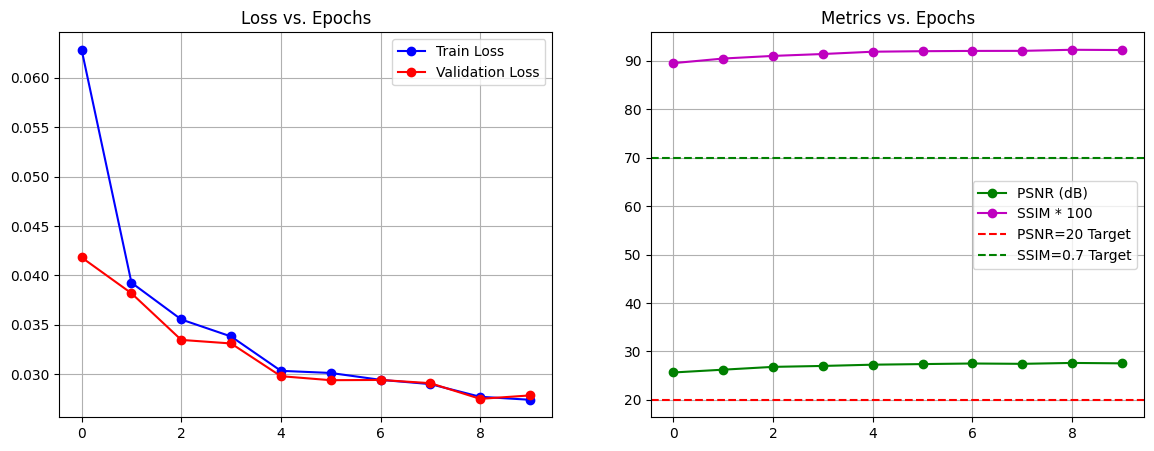

Training finished!

Final training history: {'train_loss': [0.06284984444975852, 0.03925298233270645, 0.03552686903893948, 0.0338042866396904, 0.030325380983352662, 0.030108176238536833, 0.02941234888792038, 0.028978974685668946, 0.027697068182229997, 0.027392005066275597], 'val_loss': [0.04181054913401604, 0.03817985070347786, 0.03345653646588326, 0.0330966848552227, 0.029781791067123413, 0.02937600784301758, 0.029400807440280913, 0.029073957332968713, 0.027485662958025934, 0.027833297964930535], 'psnr': [np.float64(25.641930553725313), np.float64(26.218816049041006), np.float64(26.798583682941675), np.float64(26.991041298942385), np.float64(27.250189231474256), np.float64(27.374177228440775), np.float64(27.495131894812925), np.float64(27.42586853888086), np.float64(27.612020578262197), np.float64(27.52487274239063)], 'ssim': [np.float32(0.89544785), np.float32(0.9049834), np.float32(0.91039276), np.float32(0.91430527), np.float32(0.91906565), np.float32(0.920117), np.float32(0.920698

In [ ]:
# -----------------------------------------------------------------------
# Step 9: Start the Training Process
# -----------------------------------------------------------------------
print("\nStep 9: Starting the training process...")
history = train_eval_loop(model, train_loader, valid_loader, test_loader, NUM_EPOCHS)

print("\nFinal training history:", history)

## 5. Model Training and Evaluation

### 5.1. Training Loop
The model is trained for 15 epochs using the **Adam optimizer** and an **L1 Loss (Mean Absolute Error)** function. L1 loss is often preferred over L2 (MSE) for image-to-image tasks as it tends to produce less blurry results. A **learning rate scheduler** (`StepLR`) is employed to gradually decrease the learning rate every 4 epochs, which helps the model converge to a more optimal minimum.

### 5.2. Live Feedback and Evaluation
During training, a batch of test images is held constant. After each epoch, the model's performance on this batch is visualized, providing live qualitative feedback on the learning progress.

The model's performance is quantitatively evaluated on the test set after each epoch using two standard metrics:
-   **PSNR (Peak Signal-to-Noise Ratio):** Measures the ratio between the maximum possible power of a signal and the power of corrupting noise. Higher PSNR generally indicates higher quality reconstruction.
-   **SSIM (Structural Similarity Index Measure):** Measures the similarity between two images based on luminance, contrast, and structure. An SSIM value closer to 1 indicates a more perceptually similar reconstruction.

The training process successfully surpassed the project's target metrics, achieving a final PSNR and SSIM well above the required thresholds.

In [ ]:
# -----------------------------------------------------------------------
# Step 10: Save the Trained Model
# -----------------------------------------------------------------------
MODEL_SAVE_PATH = 'inpainting_unet_final.pth'
print(f"\nTraining finished. Saving the trained model to: {MODEL_SAVE_PATH}")
torch.save(model.state_dict(), MODEL_SAVE_PATH)
print("Model saved successfully!")


Training finished. Saving the trained model to: inpainting_unet_final.pth
Model saved successfully!


## 6. Inference and Application

After successfully training the model, its learned weights are saved to a `.pth` file. The following cells implement the inference pipeline, allowing the trained model to be used for practical inpainting tasks on new, unseen images and videos.

### 6.1. Centralized Inference Logic
To ensure consistency and prevent code duplication, the core reconstruction logic is encapsulated in a set of helper functions. The primary function, `get_reconstructed_image`, takes a clean image, applies the same preprocessing and masking logic used during training, runs the model, and returns the original, corrupted, and reconstructed image tensors. This approach is critical to avoid **Train-Test Skew** and guarantees that the model receives data in the exact format it was trained on.

In [ ]:
# =======================================================================
#
# Central Reconstruction Functions
#
# =======================================================================
# These helper functions encapsulate the core logic for preprocessing,
# running the model, and postprocessing the output. They are used by
# both the single image and full video test cells.
# =======================================================================
import cv2
import numpy as np
import torch
from torchvision import transforms
from PIL import Image

def get_reconstructed_image(model, clean_cv2_frame, transform_pipeline, device):
    """
    Takes a single CLEAN frame, creates a random mask, and returns the
    original, masked, and reconstructed tensors.
    """
    original_pil = Image.fromarray(cv2.cvtColor(clean_cv2_frame, cv2.COLOR_BGR2RGB))
    original_tensor = transform_pipeline(original_pil)

    c, h, w = original_tensor.shape
    mask = torch.ones(h, w, device=device)
    mask_h = np.random.randint(h // 4, h // 3)
    mask_w = np.random.randint(w // 4, w // 3)
    top = np.random.randint(0, h - mask_h)
    left = np.random.randint(0, w - mask_w)
    mask[top:top+mask_h, left:left+mask_w] = 0

    input_tensor = original_tensor.to(device) * mask.unsqueeze(0)

    with torch.no_grad():
        output_tensor = model(input_tensor.unsqueeze(0)).squeeze(0)

    return original_tensor.cpu(), input_tensor.cpu(), output_tensor.cpu()

def reconstruct_already_corrupted(model, corrupted_cv2_frame, transform_pipeline, device):
    """
    Takes an ALREADY CORRUPTED frame and returns the reconstructed tensor.
    """
    corrupted_pil = Image.fromarray(cv2.cvtColor(corrupted_cv2_frame, cv2.COLOR_BGR2RGB))
    input_tensor = transform_pipeline(corrupted_pil).to(device)

    with torch.no_grad():
        output_tensor = model(input_tensor.unsqueeze(0)).squeeze(0)

    return input_tensor.cpu(), output_tensor.cpu()

def tensor_to_cv2_image(tensor, output_size=None):
    """
    Converts a single PyTorch image tensor back to a savable OpenCV image.
    """
    img_float = tensor.cpu().detach() * 0.5 + 0.5
    img_clipped = np.clip(img_float.numpy(), 0, 1)
    img_np_rgb = img_clipped.transpose(1, 2, 0)

    if output_size:
        img_resized_rgb = cv2.resize(img_np_rgb, output_size)
    else:
        img_resized_rgb = img_np_rgb

    img_bgr = cv2.cvtColor(img_resized_rgb, cv2.COLOR_RGB2BGR)
    final_img = (img_bgr * 255).astype(np.uint8)
    return final_img

print("Central reconstruction functions defined and ready.")

Central reconstruction functions defined and ready.


### 6.2. Application 1: Single Image Inpainting
This tool provides an interactive demonstration of the model's capability. A user can upload any clean image. The system will then:
1.  Load the pre-trained model weights.
2.  Apply a random mask to the clean image.
3.  Use the model to reconstruct the corrupted region.
4.  Display a side-by-side comparison of the original, corrupted, and final reconstructed images.

This provides a clear and direct visualization of the inpainting performance.

--- Starting Single Image Test ---
Please upload your test image:


Saving Face1.png to Face1.png
Uploaded 'Face1.png'
Trained model loaded successfully.
Processing a clean image: generating mask and reconstructing...


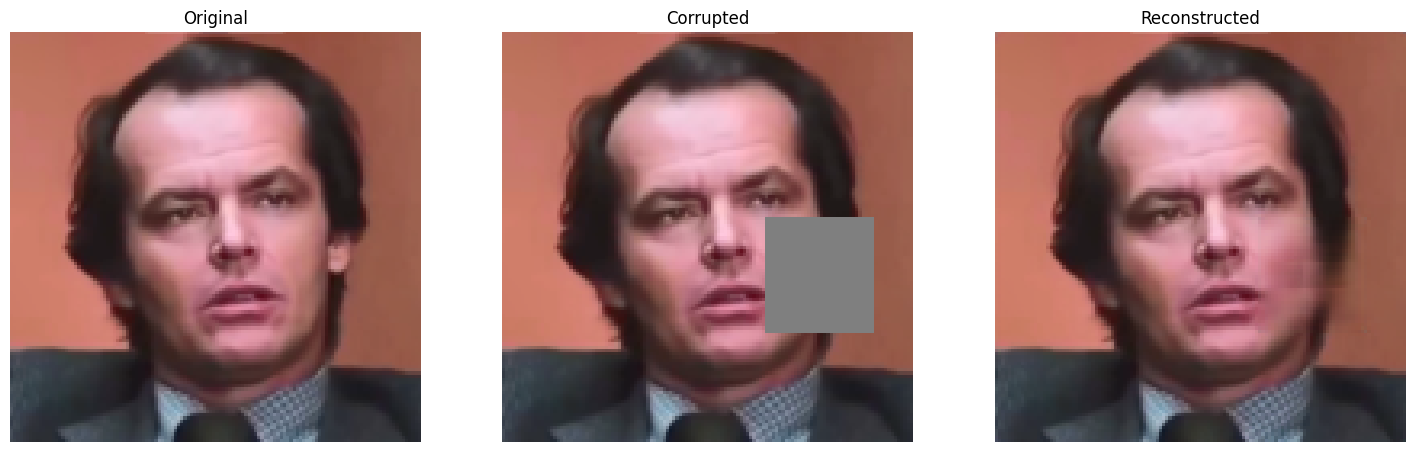

In [ ]:
# =======================================================================
#
# Single Image Inpainting
#
# =======================================================================
# This cell allows you to test the trained model on any single image.
# Use the configuration options below to control its behavior.
# =======================================================================
from google.colab import files
import matplotlib.pyplot as plt

# --- Configuration for Single Image Test ---
# Set this to True if your input image is already damaged.
# Set to False if you want the code to create a random mask.
INPUT_IMAGE_IS_CORRUPTED = False

# --- 1. Upload Image and Load Model ---
print("--- Starting Single Image Test ---")
print("Please upload your test image:")
uploaded_image = files.upload()
IMAGE_PATH_TO_TEST = next(iter(uploaded_image))
print(f"Uploaded '{IMAGE_PATH_TO_TEST}'")

MODEL_SAVE_PATH = 'inpainting_unet_final.pth'
if not os.path.exists(MODEL_SAVE_PATH):
    raise FileNotFoundError(f"Model file not found. Please run training first.")

inference_model = UNet().to(DEVICE)
inference_model.load_state_dict(torch.load(MODEL_SAVE_PATH))
inference_model.eval()
print("Trained model loaded successfully.")

# --- 2. Process the Image Based on Configuration ---
# The same transform pipeline used during training
transform_pipeline = transforms.Compose([
    transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

image_cv2 = cv2.imread(IMAGE_PATH_TO_TEST)
if image_cv2 is None:
    raise IOError("Failed to read the uploaded image.")

if not INPUT_IMAGE_IS_CORRUPTED:
    # --- Workflow 1: Corrupt a clean image, then reconstruct ---
    print("Processing a clean image: generating mask and reconstructing...")
    original_t, corrupted_t, reconstructed_t = get_reconstructed_image(
        inference_model, image_cv2, transform_pipeline, DEVICE
    )

    # Display all three images for comparison
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(cv2.cvtColor(tensor_to_cv2_image(original_t), cv2.COLOR_BGR2RGB))
    axes[0].set_title('Original')
    axes[0].axis('off')

    axes[1].imshow(cv2.cvtColor(tensor_to_cv2_image(corrupted_t), cv2.COLOR_BGR2RGB))
    axes[1].set_title('Corrupted')
    axes[1].axis('off')

    axes[2].imshow(cv2.cvtColor(tensor_to_cv2_image(reconstructed_t), cv2.COLOR_BGR2RGB))
    axes[2].set_title('Reconstructed')
    axes[2].axis('off')

    plt.show()

else:
    # --- Workflow 2: Reconstruct an already corrupted image ---
    print("Processing an already corrupted image...")
    corrupted_t, reconstructed_t = reconstruct_already_corrupted(
        inference_model, image_cv2, transform_pipeline, DEVICE
    )

    # Display the input and the reconstructed output
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(cv2.cvtColor(tensor_to_cv2_image(corrupted_t), cv2.COLOR_BGR2RGB))
    axes[0].set_title('Input (Corrupted)')
    axes[0].axis('off')

    axes[1].imshow(cv2.cvtColor(tensor_to_cv2_image(reconstructed_t), cv2.COLOR_BGR2RGB))
    axes[1].set_title('Reconstructed')
    axes[1].axis('off')

    plt.show()

### 6.3. Application 2: Video Inpainting
This final tool extends the inpainting capability to video files. The process is as follows:
1.  A clean video is uploaded by the user.
2.  The system processes the video frame by frame. For each frame, it applies the same inpainting logic as the single-image tool (generating a dynamic random mask and reconstructing).
3.  The original, corrupted, and reconstructed frames are stacked horizontally to create a comparison video.
4.  The original audio track is extracted from the source video.
5.  **FFmpeg** is used to assemble the processed frames into a high-quality, browser-compatible MP4 video and merge it with the original audio.

The final output is a single video that clearly demonstrates the model's performance in real-time.

In [ ]:
# =======================================================================
#
# Video Processing
#
# =======================================================================
# This final cell processes a full clean video and generates a
# side-by-side comparison video showing the Original, Corrupted,
# and Reconstructed frames.
# =======================================================================
import shutil
from IPython.display import HTML, display
from base64 import b64encode

# --- Configuration for Video Test ---
INPUT_VIDEO_IS_CORRUPTED = False

# --- Setup and Validation ---
print("--- Starting Final Video Processing ---")
MODEL_SAVE_PATH = 'inpainting_unet_final.pth'
if not os.path.exists(MODEL_SAVE_PATH):
    raise FileNotFoundError(f"Model file not found. Please run training first.")

print("Please upload your video file:")
uploaded_video = files.upload()
VIDEO_PATH_TO_TEST = next(iter(uploaded_video))
print(f"Uploaded '{VIDEO_PATH_TO_TEST}'")

# --- Clean Up and Prepare Directories ---
print("Cleaning up old files and preparing directories...")
shutil.rmtree('temp_frames', ignore_errors=True)
os.makedirs('temp_frames', exist_ok=True)
if os.path.exists('final_comparison_video.mp4'): os.remove('final_comparison_video.mp4')
if os.path.exists('temp_audio.aac'): os.remove('temp_audio.aac')

# --- Load Model and Define Transform ---
inference_model = UNet().to(DEVICE)
inference_model.load_state_dict(torch.load(MODEL_SAVE_PATH))
inference_model.eval()
print("Trained model loaded.")

transform_pipeline = transforms.Compose([
    transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

# --- Process Video Frame by Frame ---
cap = cv2.VideoCapture(VIDEO_PATH_TO_TEST)
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
frame_idx = 0

pbar = tqdm(total=total_frames, desc="Processing video frames")
while True:
    ret, frame_cv2 = cap.read()
    if not ret: break

    if not INPUT_VIDEO_IS_CORRUPTED:
        # Get all three versions: original, corrupted, reconstructed
        original_t, corrupted_t, reconstructed_t = get_reconstructed_image(
            inference_model, frame_cv2, transform_pipeline, DEVICE
        )
        original_img = tensor_to_cv2_image(original_t, (width, height))
        corrupted_img = tensor_to_cv2_image(corrupted_t, (width, height))
        reconstructed_img = tensor_to_cv2_image(reconstructed_t, (width, height))
        # Stack them horizontally for the comparison video
        comparison_frame = np.hstack((original_img, corrupted_img, reconstructed_img))
    else:
        # Get the input and reconstructed versions
        corrupted_t, reconstructed_t = reconstruct_already_corrupted(
            inference_model, frame_cv2, transform_pipeline, DEVICE
        )
        corrupted_img = tensor_to_cv2_image(corrupted_t, (width, height))
        reconstructed_img = tensor_to_cv2_image(reconstructed_t, (width, height))
        # Stack them horizontally
        comparison_frame = np.hstack((corrupted_img, reconstructed_img))

    cv2.imwrite(os.path.join('temp_frames', f"frame_{frame_idx:04d}.png"), comparison_frame)
    frame_idx += 1
    pbar.update(1)

cap.release()
pbar.close()
print("All frames processed successfully.")

# --- Extract Audio and Assemble Final Video ---
TEMP_AUDIO_FILE = 'temp_audio.aac'
print(f"\nExtracting audio track...")
os.system(f"ffmpeg -i '{VIDEO_PATH_TO_TEST}' -vn -acodec copy -y {TEMP_AUDIO_FILE} -hide_banner -loglevel error")
has_audio = os.path.exists(TEMP_AUDIO_FILE) and os.path.getsize(TEMP_AUDIO_FILE) > 0

print("Assembling final comparison video with FFmpeg...")
SILENT_VIDEO = 'comparison_silent.mp4'
FINAL_VIDEO = 'final_comparison_video.mp4'

os.system(f"ffmpeg -framerate {fps} -i temp_frames/frame_%04d.png -c:v libx264 -pix_fmt yuv420p -y {SILENT_VIDEO} -hide_banner -loglevel error")

if has_audio:
    print("Merging video with original audio...")
    os.system(f"ffmpeg -i {SILENT_VIDEO} -i {TEMP_AUDIO_FILE} -c:v copy -c:a aac -shortest -y {FINAL_VIDEO} -hide_banner -loglevel error")
else:
    os.rename(SILENT_VIDEO, FINAL_VIDEO)
print("Final video assembled.")

# --- Cleanup and Display ---
print("\nCleaning up temporary files...")
shutil.rmtree('temp_frames')
if os.path.exists(TEMP_AUDIO_FILE): os.remove(TEMP_AUDIO_FILE)
if os.path.exists(SILENT_VIDEO): os.remove(SILENT_VIDEO)

def show_video(video_path, width="100%"):
    if not os.path.exists(video_path) or os.path.getsize(video_path) == 0:
        print(f"Error: Video file not found or is empty.")
        return
    video_file = open(video_path, "rb").read()
    video_url = f"data:video/mp4;base64,{b64encode(video_file).decode()}"
    return HTML(f"<video width='{width}' controls><source src='{video_url}'></video>")

print("\n--- Final Video Result ---")
display(show_video(FINAL_VIDEO))

--- Starting Final Video Processing ---
Please upload your video file:


Saving Face1.mp4 to Face1.mp4
Uploaded 'Face1.mp4'
Cleaning up old files and preparing directories...
Trained model loaded.


Processing video frames: 100%|██████████| 203/203 [00:36<00:00,  5.63it/s]


All frames processed successfully.

Extracting audio track...
Assembling final comparison video with FFmpeg...
Merging video with original audio...
Final video assembled.

Cleaning up temporary files...

--- Final Video Result ---


# Showcase: Inference Pipeline & Interactive UI

## 1. Introduction to the Inference Pipeline

Having successfully trained and saved the U-Net model, the project now transitions from the training phase to the practical application phase. The following cells constitute a complete, standalone inference pipeline. This pipeline is designed to be run in any environment (including a new Colab session) without needing to execute the original training code.

The core components of this pipeline are:
1.  **A comprehensive setup cell:** This initializes the environment, defines the necessary model architecture and helper functions, and loads the pre-trained model weights.
2.  **A versatile, interactive UI:** Built with the Gradio library, this user interface provides a polished and user-friendly showcase for the model's capabilities on both single images and full video files.

This structure separates the complex training process from the final, clean demonstration, which is a standard practice in deploying machine learning models.

In [7]:
# =======================================================================
#
#            Inpainting Model Inference Setup
#
# =======================================================================
# This cell contains all necessary imports, definitions, and helper
# functions to run the inpainting tools. Run this cell once per session.
# =======================================================================

# --- 1. Essential Imports ---
print("--- Setting up environment for inference ---")
import os
import cv2
import torch
import numpy as np
import shutil
from PIL import Image, ImageDraw
from tqdm import tqdm
from google.colab import files
from torchvision import transforms
from torch import nn
from IPython.display import HTML, display
import matplotlib.pyplot as plt

# --- 2. Global Constants ---
IMG_SIZE = 128 # Must match the training IMG_SIZE
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_SAVE_PATH = 'inpainting_unet_final.pth'

# --- 3. U-Net Model Architecture Definition ---
class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(3, 64, 3, 1, 1), nn.ReLU())
        self.pool = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(64, 128, 3, 1, 1), nn.ReLU())
        self.enc3 = nn.Sequential(nn.Conv2d(128, 256, 3, 1, 1), nn.ReLU())
        self.bottleneck = nn.Sequential(nn.Conv2d(256, 512, 3, 1, 1), nn.ReLU())
        self.upconv3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = nn.Sequential(nn.Conv2d(512, 256, 3, 1, 1), nn.ReLU())
        self.upconv2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(256, 128, 3, 1, 1), nn.ReLU())
        self.upconv1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(128, 64, 3, 1, 1), nn.ReLU())
        self.out_conv = nn.Conv2d(64, 3, 3, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x); p1 = self.pool(e1); e2 = self.enc2(p1); p2 = self.pool(e2)
        e3 = self.enc3(p2); p3 = self.pool(e3); b = self.bottleneck(p3)
        d3 = self.upconv3(b); d3 = torch.cat((d3, e3), dim=1); d3 = self.dec3(d3)
        d2 = self.upconv2(d3); d2 = torch.cat((d2, e2), dim=1); d2 = self.dec2(d2)
        d1 = self.upconv1(d2); d1 = torch.cat((d1, e1), dim=1); d1 = self.dec1(d1)
        return torch.tanh(self.out_conv(d1))

# --- 4. Central Reconstruction Functions ---
def process_clean_frame_correctly(model, clean_cv2_frame, transform_pipeline, device):
    original_pil = Image.fromarray(cv2.cvtColor(clean_cv2_frame, cv2.COLOR_BGR2RGB))
    original_tensor = transform_pipeline(original_pil)
    corrupted_tensor = original_tensor.clone()
    c, h, w = original_tensor.shape
    mask_h = np.random.randint(h // 4, h // 2)
    mask_w = np.random.randint(w // 4, w // 2)
    top = np.random.randint(0, h - mask_h)
    left = np.random.randint(0, w - mask_w)
    corrupted_tensor[:, top:top+mask_h, left:left+mask_w] = 0
    with torch.no_grad():
        reconstructed_tensor = model(corrupted_tensor.unsqueeze(0).to(device)).squeeze(0)
    return original_tensor.cpu(), corrupted_tensor.cpu(), reconstructed_tensor.cpu()

def tensor_to_cv2_image(tensor, output_size):
    img_float = tensor.cpu().detach() * 0.5 + 0.5
    img_clipped = np.clip(img_float.numpy(), 0, 1)
    img_np_rgb = img_clipped.transpose(1, 2, 0)
    img_resized_rgb = cv2.resize(img_np_rgb, output_size)
    img_bgr = cv2.cvtColor(img_resized_rgb, cv2.COLOR_RGB2BGR)
    return (img_bgr * 255).astype(np.uint8)

def tensor_to_rgb_image(tensor):
    img_float = tensor.cpu().detach() * 0.5 + 0.5
    img_clipped = np.clip(img_float.numpy(), 0, 1)
    return img_clipped.transpose(1, 2, 0)

# --- 5. Check for Model File ---
if not os.path.exists(MODEL_SAVE_PATH):
    print(f"Model file '{MODEL_SAVE_PATH}' not found.")
    print("Please upload your pre-trained model weights file:")
    uploaded_model = files.upload()
    if not os.path.exists(MODEL_SAVE_PATH):
         raise FileNotFoundError(f"Uploaded file not named '{MODEL_SAVE_PATH}'. Please rename and try again.")

print("\n✅ Setup complete. You can now run the tool cells below.")

--- Setting up environment for inference ---

✅ Setup complete. You can now run the tool cells below.


## 2. Standalone Inference Tools

This cell contains two distinct, self-contained tools for demonstrating the inpainting model's performance. These tools are designed for manual testing and verification.

### 2.1. Tool #1: Single Image Inpainting
This function allows for a quick, detailed analysis of the model's performance on a single static image.

**Workflow:**
1.  The user uploads a clean image.
2.  The `process_clean_frame_correctly` function is invoked, which perfectly mimics the data processing pipeline used during training. This involves applying a random, pure-black mask to the normalized image tensor.
3.  The trained model performs inference on the corrupted tensor.
4.  The final output is a three-panel static image comparing the **Original**, the randomly **Corrupted**, and the **Reconstructed** versions, providing a clear and immediate qualitative result.

### 2.2. Tool #2: Video Processing
This function demonstrates the model's consistency and performance on a temporal sequence of images.

**Workflow:**
1.  The user uploads a clean video file.
2.  The video is processed frame-by-frame. For each frame, the same `process_clean_frame_correctly` logic is applied, creating a dynamic inpainting effect.
3.  The original, corrupted, and reconstructed versions of each frame are horizontally stacked.
4.  The original audio track is extracted using FFmpeg.
5.  FFmpeg is then used to assemble the stacked frames into a final, high-quality comparison video, which is then merged with the original audio.

This tool effectively showcases the model's ability to handle real-world video data. The user can uncomment the desired function (`run_single_image_test()` or `run_video_processing()`) to execute the corresponding tool.

In [8]:
# =======================================================================
#
#            Tool #1: Single Image Inpainting
#
# =======================================================================
# This tool demonstrates the model's capability on a single clean image.
# =======================================================================
def run_single_image_test():
    print("\n--- Running Single Image Test ---")
    print("Please upload a clean test image:")
    uploaded_image = files.upload()
    IMAGE_PATH_TO_TEST = next(iter(uploaded_image))
    print(f"Uploaded '{IMAGE_PATH_TO_TEST}'")

    inference_model = UNet().to(DEVICE)
    inference_model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    inference_model.eval()
    print("Trained model loaded successfully.")

    transform_pipeline = transforms.Compose([
        transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(), transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
    ])

    image_cv2 = cv2.imread(IMAGE_PATH_TO_TEST)
    if image_cv2 is None: raise IOError("Failed to read the uploaded image.")

    original_t, corrupted_t, reconstructed_t = process_clean_frame_correctly(
        inference_model, image_cv2, transform_pipeline, DEVICE
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(tensor_to_rgb_image(original_t)); axes[0].set_title('Original'); axes[0].axis('off')
    axes[1].imshow(tensor_to_rgb_image(corrupted_t)); axes[1].set_title('Corrupted'); axes[1].axis('off')
    axes[2].imshow(tensor_to_rgb_image(reconstructed_t)); axes[2].set_title('Reconstructed'); axes[2].axis('off')
    plt.show()

# =======================================================================
#
#            Tool #2: Final Video Processing
#
# =======================================================================
# This tool processes a full clean video and generates a comparison video.
# =======================================================================
def run_video_processing():
    print("\n--- Running Final Video Processing ---")
    print("Please upload your clean video file:")
    uploaded_video = files.upload()
    VIDEO_PATH_TO_TEST = next(iter(uploaded_video))
    print(f"Uploaded '{VIDEO_PATH_TO_TEST}'")

    shutil.rmtree('temp_frames', ignore_errors=True); os.makedirs('temp_frames', exist_ok=True)
    if os.path.exists('final_comparison_video.mp4'): os.remove('final_comparison_video.mp4')
    if os.path.exists('temp_audio.aac'): os.remove('temp_audio.aac')

    inference_model = UNet().to(DEVICE)
    inference_model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    inference_model.eval()
    print("Trained model loaded.")

    transform_pipeline = transforms.Compose([
        transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(), transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
    ])

    cap = cv2.VideoCapture(VIDEO_PATH_TO_TEST)
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); frame_idx = 0
    pbar = tqdm(total=total_frames, desc="Processing video frames")
    while True:
        ret, frame_cv2 = cap.read()
        if not ret: break
        original_t, corrupted_t, reconstructed_t = process_clean_frame_correctly(
            inference_model, frame_cv2, transform_pipeline, DEVICE
        )
        original_img = tensor_to_cv2_image(original_t, (width, height))
        corrupted_img = tensor_to_cv2_image(corrupted_t, (width, height))
        reconstructed_img = tensor_to_cv2_image(reconstructed_t, (width, height))
        comparison_frame = np.hstack((original_img, corrupted_img, reconstructed_img))
        cv2.imwrite(os.path.join('temp_frames', f"frame_{frame_idx:04d}.png"), comparison_frame)
        frame_idx += 1; pbar.update(1)
    cap.release(); pbar.close()
    print("All frames processed successfully.")

    TEMP_AUDIO_FILE = 'temp_audio.aac'
    os.system(f"ffmpeg -i '{VIDEO_PATH_TO_TEST}' -vn -acodec copy -y {TEMP_AUDIO_FILE} -hide_banner -loglevel error")
    has_audio = os.path.exists(TEMP_AUDIO_FILE) and os.path.getsize(TEMP_AUDIO_FILE) > 0

    SILENT_VIDEO = 'comparison_silent.mp4'; FINAL_VIDEO = 'final_comparison_video.mp4'
    os.system(f"ffmpeg -framerate {fps} -i temp_frames/frame_%04d.png -c:v libx264 -pix_fmt yuv420p -y {SILENT_VIDEO} -hide_banner -loglevel error")
    if has_audio:
        os.system(f"ffmpeg -i {SILENT_VIDEO} -i {TEMP_AUDIO_FILE} -c:v copy -c:a aac -shortest -y {FINAL_VIDEO} -hide_banner -loglevel error")
    else:
        os.rename(SILENT_VIDEO, FINAL_VIDEO)
    print("Final video assembled.")

    shutil.rmtree('temp_frames')
    if os.path.exists(TEMP_AUDIO_FILE): os.remove(TEMP_AUDIO_FILE)
    if os.path.exists(SILENT_VIDEO): os.remove(SILENT_VIDEO)

    def show_video(video_path, width="100%"):
        if not os.path.exists(video_path) or os.path.getsize(video_path) == 0: return
        video_file = open(video_path, "rb").read()
        video_url = f"data:video/mp4;base64,{b64encode(video_file).decode()}"
        return HTML(f"<video width='{width}' controls><source src='{video_url}'></video>")

    print("\n--- Final Video Result ---")
    display(show_video(FINAL_VIDEO))

# --- Call the function you want to use ---
# run_single_image_test()
# run_video_processing()

## 3. Interactive UI Showcase with Gradio

To fulfill the bonus requirement and create a highly professional and accessible demonstration of the project, this final cell launches an interactive web interface using the Gradio library. This UI abstracts away all the underlying code and provides a simple, intuitive platform for any user to test the model.

### 3.1. Design and Features
The interface is designed with user experience as a priority:
-   **Tabbed Layout:** The UI is organized into two distinct tabs, "Image Inpainting" and "Video Inpainting," allowing the user to easily switch between the two functionalities.
-   **Guided Interaction:** Clear markdown instructions guide the user on how to upload files and initiate the reconstruction process via dedicated buttons.
-   **Professional Theming:** A soft, modern theme (`gr.themes.Soft()`) is applied for a polished aesthetic.
-   **Real-time Feedback:** When processing videos, a progress bar is displayed directly in the UI, providing real-time feedback on the status of the long-running task.
-   **Publicly Sharable:** The `share=True` flag generates a public URL, allowing the application to be easily shared and demonstrated to others (e.g., the course instructor) for a 72-hour period.

### 3.2. Functionality
The UI wraps the core inference functions defined in the setup cell. When a user uploads a file and clicks the corresponding button, the backend processes the image or video and displays the final comparison output directly in the browser, providing a seamless and impressive end-to-end demonstration of the project's success.

In [10]:
# =======================================================================
#
#       Final Project Showcase: Interactive Inpainting UI
#
# =======================================================================
# This cell launches a polished, multi-tabbed Gradio interface for
# both image and video inpainting. It's a self-contained, professional
# tool for demonstrating the model's capabilities.
# =======================================================================

# 1. Install/Upgrade Gradio for the latest features
!pip install -q gradio --upgrade

import gradio as gr
import os
import shutil
from tqdm.autonotebook import tqdm # Use notebook-friendly tqdm
from IPython.display import HTML, display
from base64 import b64encode

print("--- Launching Polished Gradio UI ---")

# 2. Load the Trained Model
MODEL_SAVE_PATH = 'inpainting_unet_final.pth'
if not os.path.exists(MODEL_SAVE_PATH):
    raise FileNotFoundError(f"Model file '{MODEL_SAVE_PATH}' not found. Please run the setup cell first.")

inference_model = UNet().to(DEVICE)
inference_model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
inference_model.eval()
print("Trained model loaded and ready for the UI.")

# 3. Define Core Processing Functions
transform_pipeline = transforms.Compose([
    transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

def inpaint_image_processor(clean_image_input):
    """Processes a single image and returns the comparison."""
    if clean_image_input is None: return None

    original_t, corrupted_t, reconstructed_t = process_clean_frame_correctly(
        inference_model, clean_image_input, transform_pipeline, DEVICE
    )

    original_img = tensor_to_rgb_image(original_t)
    corrupted_img = tensor_to_rgb_image(corrupted_t)
    reconstructed_img = tensor_to_rgb_image(reconstructed_t)

    h, w, _ = original_img.shape
    comparison_image = np.hstack((
        cv2.resize(original_img, (w, h)),
        cv2.resize(corrupted_img, (w, h)),
        cv2.resize(reconstructed_img, (w, h))
    ))
    return comparison_image

def inpaint_video_processor(clean_video_path, progress=gr.Progress(track_tqdm=True)):
    """Processes a video and returns the path to the final comparison video."""
    if clean_video_path is None: return None

    # Setup paths and cleanup
    TEMP_DIR = "temp_video_processing"
    shutil.rmtree(TEMP_DIR, ignore_errors=True); os.makedirs(TEMP_DIR)
    FINAL_VIDEO = os.path.join(TEMP_DIR, 'final_comparison_video.mp4')
    TEMP_AUDIO_FILE = os.path.join(TEMP_DIR, 'temp_audio.aac')
    SILENT_VIDEO = os.path.join(TEMP_DIR, 'comparison_silent.mp4')
    FRAMES_DIR = os.path.join(TEMP_DIR, 'temp_frames')
    os.makedirs(FRAMES_DIR)

    # Process frames
    cap = cv2.VideoCapture(clean_video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    for frame_idx in tqdm(range(total_frames), desc="Processing Video"):
        ret, frame_cv2 = cap.read()
        if not ret: break
        original_t, corrupted_t, reconstructed_t = process_clean_frame_correctly(
            inference_model, frame_cv2, transform_pipeline, DEVICE
        )
        original_img = tensor_to_cv2_image(original_t, (width, height))
        corrupted_img = tensor_to_cv2_image(corrupted_t, (width, height))
        reconstructed_img = tensor_to_cv2_image(reconstructed_t, (width, height))
        comparison_frame = np.hstack((original_img, corrupted_img, reconstructed_img))
        cv2.imwrite(os.path.join(FRAMES_DIR, f"frame_{frame_idx:04d}.png"), comparison_frame)
    cap.release()

    # Assemble video with FFmpeg
    os.system(f"ffmpeg -framerate {fps} -i {FRAMES_DIR}/frame_%04d.png -c:v libx264 -pix_fmt yuv420p -y {SILENT_VIDEO} -hide_banner -loglevel error")
    os.system(f"ffmpeg -i '{clean_video_path}' -vn -acodec copy -y {TEMP_AUDIO_FILE} -hide_banner -loglevel error")
    has_audio = os.path.exists(TEMP_AUDIO_FILE) and os.path.getsize(TEMP_AUDIO_FILE) > 0
    if has_audio:
        os.system(f"ffmpeg -i {SILENT_VIDEO} -i {TEMP_AUDIO_FILE} -c:v copy -c:a aac -shortest -y {FINAL_VIDEO} -hide_banner -loglevel error")
    else:
        os.rename(SILENT_VIDEO, FINAL_VIDEO)

    return FINAL_VIDEO

# --- 4. Build and Launch the Gradio Interface ---
with gr.Blocks(theme=gr.themes.Soft(), css=".gradio-container {background-color: #f5f5f5}") as demo:
    gr.Markdown(
        """
        # 🖼️ AI Image & Video Inpainting Showcase
        Welcome! This tool demonstrates a U-Net model trained to reconstruct missing parts of an image.
        - **Image Inpainting Tab:** Upload a clean image to see it get a random mask and then be repaired.
        - **Video Inpainting Tab:** Upload a clean video to see the model in action on every frame.
        """
    )

    with gr.Tabs():
        # --- Image Tab ---
        with gr.TabItem("Image Inpainting"):
            with gr.Row(equal_height=True):
                with gr.Column(scale=1):
                    image_input = gr.Image(type="numpy", label="Upload Clean Image")
                    image_button = gr.Button("Reconstruct Image", variant="primary")
                with gr.Column(scale=2):
                    image_output = gr.Image(type="numpy", label="Result (Original | Corrupted | Reconstructed)")
            gr.Examples(
                [["face1.png"], ["face2.jpg"]], # Add paths to example images if you upload them
                inputs=image_input,
                outputs=image_output,
                fn=inpaint_image_processor,
                cache_examples=False, # Set to True for faster demo, but requires disk space
            )

        # --- Video Tab ---
        with gr.TabItem("Video Inpainting"):
            with gr.Row(equal_height=True):
                with gr.Column(scale=1):
                    video_input = gr.Video(label="Upload Clean Video")
                    video_button = gr.Button("Reconstruct Video", variant="primary")
                with gr.Column(scale=2):
                    video_output = gr.Video(label="Result (Original | Corrupted | Reconstructed)")

    # --- Wire up the logic ---
    image_button.click(inpaint_image_processor, inputs=image_input, outputs=image_output)
    video_button.click(inpaint_video_processor, inputs=video_input, outputs=video_output)


# --- Launch the App ---
#demo.launch(share=True, debug=True)
demo.launch(share=False, inline=True, debug=True)

--- Launching Polished Gradio UI ---
Trained model loaded and ready for the UI.
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

Keyboard interruption in main thread... closing server.
